<a href="https://colab.research.google.com/github/MenadiDev/PUSL3123_Group_18/blob/main/Exercise4_Width_Depth.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exercise 4 - Effect of model width and depth

Six CNN variants are compared (all other settings identical to Exercises 2-3: same 45,000/5,000 train/validation split, Adam lr = 0.001, batch size 128, 30 epochs, best epoch chosen on validation accuracy, test set evaluated once at the end)
- **Width** (2 conv layers, second layer has twice the channels of the first): [16,32], [32,64], [64,128]
- **Depth** (every conv layer has 32 channels; pooling after the first 3 conv layers only): 1, 3 and 5 conv layers

Each variant is trained with **3 random seeds (0, 1, 2)**; results are reported as mean ± standard deviation, and the graphs show error bars (±1 std).

**Runtime:** 18 trainings - use a GPU (roughly 1.5-2.5 hours; far longer on a CPU). Progress is saved to `ex4_checkpoint.json` after every run.

**1. Setting up the environment**

In [1]:
import os, time, copy, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

EPOCHS = 30
LR = 1e-3
BATCH_SIZE = 128
NUM_WORKERS = 2
ROOT = "./data"
os.makedirs("figures", exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available() else "cpu")
print("Using device:", DEVICE)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

Using device: cuda


**2. Dataset Preparation and Data Loading**

In [2]:
#Defining CIFAR-10 Dataset Config

CLASSES = ["aeroplane","automobile","bird","cat","deer","dog","frog","horse","ship","truck"]
MEAN, STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)

#Image Transformations
eval_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

## applying data augmentation  to training images
aug_tf = transforms.Compose([
    transforms.RandomAffine(degrees=10, translate=(0.1, 0.1)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

#dataset loading
train_eval_full = datasets.CIFAR10(ROOT, train=True,  download=True,  transform=eval_tf)
train_aug_full  = datasets.CIFAR10(ROOT, train=True,  download=False, transform=aug_tf)
test_set        = datasets.CIFAR10(ROOT, train=False, download=True,  transform=eval_tf)

perm = torch.randperm(50000, generator=torch.Generator().manual_seed(42)).tolist()
train_idx, val_idx = perm[:45000], perm[45000:]
print(f"train={len(train_idx)}  val={len(val_idx)}  test={len(test_set)}")

#dataloaders
def make_loaders(augment=False, seed=0):

    g = torch.Generator().manual_seed(seed)
    src = train_aug_full if augment else train_eval_full

    # Training loader
    train_loader = DataLoader(Subset(src, train_idx), batch_size=BATCH_SIZE, shuffle=True,
                              num_workers=NUM_WORKERS, generator=g)

    # Clean training loader for consistent model evaluation
    clean_train = DataLoader(Subset(train_eval_full, train_idx), batch_size=512, num_workers=NUM_WORKERS)

    #validation loader
    val_loader  = DataLoader(Subset(train_eval_full, val_idx),   batch_size=512, num_workers=NUM_WORKERS)

    #independent test loader
    test_loader = DataLoader(test_set, batch_size=512, num_workers=NUM_WORKERS)
    return train_loader, clean_train, val_loader, test_loader

100%|██████████| 170M/170M [26:08<00:00, 109kB/s] 


train=45000  val=5000  test=10000


**3. Model Training and Evaluation**

i. Model Training and Performance Evaluation

In [3]:

# Calculating the total number of trainable parameters
def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def run_epoch(model, loader, optimizer=None):


    train = optimizer is not None
    model.train(train)

    tot_loss = tot_correct = n = 0

    # Enabling gradient calculation only during training
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)

            # Forward pass
            out = model(x)
            loss = F.cross_entropy(out, y)

            # Backpropagation
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            # Accumulate loss and correct predictions
            tot_loss += loss.item() * len(y)
            tot_correct += (out.argmax(1) == y).sum().item()
            n += len(y)

    # Return average loss and accuracy for the epoch
    return tot_loss / n, tot_correct / n



def train_model(model, loaders, epochs=EPOCHS, lr=LR, verbose=True):

    train_loader, clean_train, val_loader, test_loader = loaders
    model.to(DEVICE)


    opt = torch.optim.Adam(model.parameters(), lr=lr)


    hist = {k: [] for k in ["train_loss", "val_loss", "train_acc", "val_acc"]}


    best_val, best_state, best_epoch, t0 = -1, None, 0, time.time()

    for ep in range(1, epochs + 1):

        # Perform training and validation for the current epoch
        tl, ta = run_epoch(model, train_loader, opt)
        vl, va = run_epoch(model, val_loader)


        for k, v in zip(hist, [tl, vl, ta, va]):
            hist[k].append(v)


        if va > best_val:
            best_val, best_epoch, best_state = va, ep, copy.deepcopy(model.state_dict())


        if verbose and (ep % 5 == 0 or ep == 1):
            print(f"ep {ep:02d} | train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f}")

    # Restoring the model checkpoint with the highest validation accuracy
    model.load_state_dict(best_state)

    # Evaluating the selected model on clean training, validation and test data
    ctl, cta = run_epoch(model, clean_train)
    vl, va = run_epoch(model, val_loader)
    tel, tea = run_epoch(model, test_loader)


    res = dict(
        params=count_params(model),
        best_epoch=best_epoch,
        train_loss=ctl,
        train_acc=cta,
        val_loss=vl,
        val_acc=va,
        test_loss=tel,
        test_acc=tea,
        gap=cta - tea,
        final_epoch_train_loss=hist["train_loss"][-1],
        time_s=time.time() - t0
    )

    return hist, res

ii. Visualizing Training History

In [4]:

# Plot training and validation loss and accuracy across epochs
def plot_history(hist, title, fname=None):

    ep = range(1, len(hist["train_loss"]) + 1)


    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))

    # Plot training and validation loss
    ax[0].plot(ep, hist["train_loss"], label="Training")
    ax[0].plot(ep, hist["val_loss"], label="Validation")
    ax[0].set(title=f"{title}: loss", xlabel="Epoch", ylabel="Cross-entropy loss")
    ax[0].legend()
    ax[0].grid(alpha=.3)

    # Plot training and validation accuracy
    ax[1].plot(ep, hist["train_acc"], label="Training")
    ax[1].plot(ep, hist["val_acc"], label="Validation")
    ax[1].set(title=f"{title}: accuracy", xlabel="Epoch", ylabel="Accuracy")
    ax[1].legend()
    ax[1].grid(alpha=.3)

    plt.tight_layout()

    if fname:
        plt.savefig(f"figures/{fname}.png", dpi=200)

    plt.show()

iii. Confusion Matrix Analysis and Visualization

In [5]:

@torch.no_grad()
def confusion(model, loader):

    model.eval()
    cm = np.zeros((10, 10), dtype=int)

    for x, y in loader:

        # Generate predictions without calculating gradients
        p = model(x.to(DEVICE)).argmax(1).cpu().numpy()

        # Count actual and predicted class combinations
        for t, q in zip(y.numpy(), p):
            cm[t, q] += 1

    return cm



def plot_confusion(cm, title, fname=None):

    plt.figure(figsize=(6.2, 5.4))
    plt.imshow(cm, cmap="Blues")
    plt.colorbar()


    plt.xticks(range(10), CLASSES, rotation=60, ha="right")
    plt.yticks(range(10), CLASSES)

    for i in range(10):
        for j in range(10):
            plt.text(
                j, i, cm[i, j],
                ha="center",
                va="center",
                fontsize=6,
                color="white" if cm[i, j] > cm.max() / 2 else "black"
            )

    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.tight_layout()

    if fname:
        plt.savefig(f"figures/{fname}.png", dpi=200)

    plt.show()

**4. Defining Neural Network Architecture**s

**i. MLP Architecture**

In [6]:
class MLP(nn.Module):

    def __init__(self, h1=512, h2=256):
        super().__init__()

        # Defining fully connected layers with ReLU activation
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3 * 32 * 32, h1),
            nn.ReLU(),
            nn.Linear(h1, h2),
            nn.ReLU(),
            nn.Linear(h2, 10)
        )

    # Forward pass through the network
    def forward(self, x):
        return self.net(x)

**ii. CNN Architecture**

In [7]:
def build_cnn(channels, dropout=0.0, max_pools=3, n_classes=10):

    layers, c = [], 3

    # Construct convolutional blocks with ReLU activation
    for i, ch in enumerate(channels):
        layers += [
            nn.Conv2d(c, ch, 3, padding=1),
            nn.ReLU()
        ]

        if i < max_pools:
            layers.append(nn.MaxPool2d(2))

        c = ch


    layers.append(nn.Flatten())

    with torch.no_grad():
        d = nn.Sequential(*layers)(
            torch.zeros(1, 3, 32, 32)
        ).shape[1]


    if dropout > 0:
        layers.append(nn.Dropout(dropout))


    layers.append(nn.Linear(d, n_classes))

    return nn.Sequential(*layers)

**5. CNN Architecture Experiments – Width and Depth Comparison**

In [8]:
import json

SEEDS = [0, 1, 2]

VARIANTS = {
    "W1 [16,32]":  ("width", 1, [16, 32]),
    "W2 [32,64]":  ("width", 2, [32, 64]),
    "W3 [64,128]": ("width", 3, [64, 128]),
    "D1 (1 conv)": ("depth", 1, [32]),
    "D2 (3 conv)": ("depth", 2, [32, 32, 32]),
    "D3 (5 conv)": ("depth", 3, [32, 32, 32, 32, 32]),
}


CKPT = "ex4_checkpoint.json"
rows, hists = [], {}

if os.path.exists(CKPT):
    saved = json.load(open(CKPT))
    rows = saved["rows"]
    hists = {
        (k.rsplit("||", 1)[0], int(k.rsplit("||", 1)[1])): v
        for k, v in saved["hists"].items()
    }
    print(f"Resuming: {len(rows)} runs already finished")

done = {(r["variant"], r["seed"]) for r in rows}

# Training each architecture using multiple random seeds
for name, (kind, level, ch) in VARIANTS.items():
    for s in SEEDS:

        if (name, s) in done:
            print(f"{name:14s} seed {s}: already done, skipping")
            continue

        set_seed(s)
        loaders = make_loaders(augment=False, seed=s)

        m = build_cnn(ch)
        h, r = train_model(m, loaders, verbose=False)

        rows.append(dict(variant=name, kind=kind, level=level, seed=s, **r))
        hists[(name, s)] = h

        # Updating checkpoint after each completed run
        json.dump(
            {
                "rows": rows,
                "hists": {f"{k[0]}||{k[1]}": v for k, v in hists.items()}
            },
            open(CKPT, "w")
        )

        print(
            f"{name:14s} seed {s} | params {r['params']:>8,d} "
            f"| train loss {r['train_loss']:.3f} "
            f"| val acc {r['val_acc']:.3f} "
            f"| test acc {r['test_acc']:.3f} "
            f"| {r['time_s']/60:.1f} min"
        )



raw = pd.DataFrame(rows)
raw.to_csv("ex4_raw_results.csv", index=False)

W1 [16,32]     seed 0 | params   25,578 | train loss 0.578 | val acc 0.690 | test acc 0.685 | 5.4 min
W1 [16,32]     seed 1 | params   25,578 | train loss 0.582 | val acc 0.688 | test acc 0.687 | 5.4 min
W1 [16,32]     seed 2 | params   25,578 | train loss 0.642 | val acc 0.687 | test acc 0.689 | 5.4 min
W2 [32,64]     seed 0 | params   60,362 | train loss 0.421 | val acc 0.714 | test acc 0.719 | 5.5 min
W2 [32,64]     seed 1 | params   60,362 | train loss 0.390 | val acc 0.712 | test acc 0.716 | 5.6 min
W2 [32,64]     seed 2 | params   60,362 | train loss 0.464 | val acc 0.716 | test acc 0.719 | 5.6 min
W3 [64,128]    seed 0 | params  157,578 | train loss 0.378 | val acc 0.731 | test acc 0.724 | 5.7 min
W3 [64,128]    seed 1 | params  157,578 | train loss 0.431 | val acc 0.725 | test acc 0.721 | 5.7 min
W3 [64,128]    seed 2 | params  157,578 | train loss 0.462 | val acc 0.734 | test acc 0.730 | 5.9 min
D1 (1 conv)    seed 0 | params   82,826 | train loss 0.612 | val acc 0.654 | test 

**6. Results Summary**

In [9]:
# Calculating Mean and Standard Deviation

raw["train_val_gap"] = raw["train_acc"] - raw["val_acc"]

metrics = [
    "train_loss", "final_epoch_train_loss", "train_acc",
    "val_acc", "test_acc", "train_val_gap",
    "val_loss", "best_epoch", "time_s"
]

grp = raw.groupby(["variant", "kind", "level"], sort=False)

res = grp[["params"] + metrics].mean().reset_index()
res_std = grp[metrics].std().reset_index().fillna(0)



def pm(m, digits=3, scale=1):
    return [
        f"{a*scale:.{digits}f} +/- {b*scale:.{digits}f}"
        for a, b in zip(res[m], res_std[m])
    ]


tbl = pd.DataFrame({
    "Variant": res["variant"],
    "Params": res["params"].astype(int),
    "Train loss (best epoch)": pm("train_loss"),
    "Train acc (%)": pm("train_acc", 2, 100),
    "Val acc (%)": pm("val_acc", 2, 100),
    "Test acc (%)": pm("test_acc", 2, 100),
    "Train-val gap (pp)": pm("train_val_gap", 2, 100),
    "Best epoch": pm("best_epoch", 1),
    "Time / run (min)": pm("time_s", 1, 1/60),
})

display(tbl)


#exporting summary tables
res.merge(
    res_std[["variant"] + metrics].add_suffix("_std").rename(
        columns={"variant_std": "variant"}
    ),
    on="variant"
).round(5).to_csv("ex4_summary.csv", index=False)


tbl.to_csv("ex4_summary_formatted.csv", index=False)

,Variant,Params,Train loss (best epoch),Train acc (%),Val acc (%),Test acc (%),Train-val gap (pp),Best epoch,Time / run (min)
0,"W1 [16,32]",25578,0.601 +/- 0.036,79.50 +/- 1.10,68.82 +/- 0.15,68.68 +/- 0.23,10.68 +/- 0.96,18.3 +/- 2.9,5.4 +/- 0.0
1,"W2 [32,64]",60362,0.425 +/- 0.037,85.78 +/- 1.33,71.43 +/- 0.20,71.76 +/- 0.18,14.36 +/- 1.52,11.3 +/- 1.5,5.6 +/- 0.1
2,"W3 [64,128]",157578,0.424 +/- 0.042,85.89 +/- 1.43,72.96 +/- 0.46,72.52 +/- 0.46,12.93 +/- 1.60,7.3 +/- 1.2,5.8 +/- 0.1
3,D1 (1 conv),82826,0.594 +/- 0.028,80.25 +/- 1.05,65.63 +/- 0.20,64.84 +/- 0.45,14.63 +/- 1.04,13.3 +/- 1.5,5.5 +/- 0.0
4,D2 (3 conv),24522,0.506 +/- 0.036,82.64 +/- 1.27,73.41 +/- 0.25,73.20 +/- 0.75,9.23 +/- 1.10,21.7 +/- 2.5,5.8 +/- 0.1
5,D3 (5 conv),43018,0.368 +/- 0.025,87.28 +/- 0.67,73.82 +/- 0.49,73.32 +/- 0.48,13.46 +/- 0.28,20.0 +/- 1.7,6.0 +/- 0.0


**7. Visualising Experiment Results**

i. Comparative Performance and Model Complexity

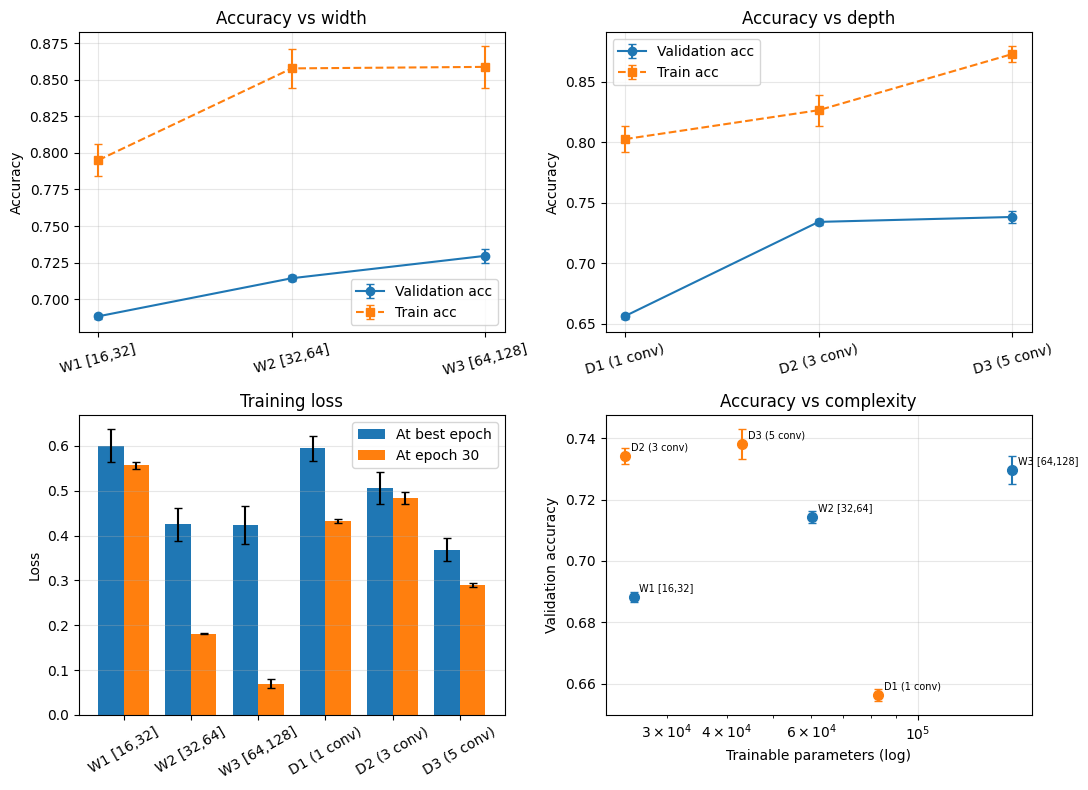

In [10]:
W, D = res[res.kind == "width"], res[res.kind == "depth"]
Ws, Ds = res_std[res_std.kind == "width"], res_std[res_std.kind == "depth"]

fig, ax = plt.subplots(2, 2, figsize=(11, 8))



# Plotting validation and training accuracy with standard deviation error bars
for a, d, ds, t in [
    (ax[0, 0], W, Ws, "width"),
    (ax[0, 1], D, Ds, "depth")
]:
    x = np.arange(len(d))

    a.errorbar(x, d["val_acc"], yerr=ds["val_acc"],
               fmt="o-", capsize=3, label="Validation acc")

    a.errorbar(x, d["train_acc"], yerr=ds["train_acc"],
               fmt="s--", capsize=3, label="Train acc")

    a.set_xticks(x)
    a.set_xticklabels(d["variant"], rotation=15)
    a.set(title=f"Accuracy vs {t}", ylabel="Accuracy")
    a.legend()
    a.grid(alpha=.3)



# Training Loss Comparison
x = np.arange(len(res))
w = 0.38

ax[1, 0].bar(
    x - w/2, res["train_loss"], w,
    yerr=res_std["train_loss"], capsize=3, label="At best epoch"
)

ax[1, 0].bar(
    x + w/2, res["final_epoch_train_loss"], w,
    yerr=res_std["final_epoch_train_loss"], capsize=3, label="At epoch 30"
)

ax[1, 0].set_xticks(x)
ax[1, 0].set_xticklabels(res["variant"], rotation=30)
ax[1, 0].set(title="Training loss", ylabel="Loss")
ax[1, 0].legend()
ax[1, 0].grid(axis="y", alpha=.3)



# Validation Accuracy vs Model Complexity
for idx, r in res.iterrows():

    col = "tab:blue" if r["kind"] == "width" else "tab:orange"

    ax[1, 1].errorbar(
        r["params"], r["val_acc"],
        yerr=res_std.loc[idx, "val_acc"],
        fmt="o", color=col, capsize=3, ms=7
    )

    ax[1, 1].annotate(
        r["variant"], (r["params"], r["val_acc"]),
        fontsize=7, xytext=(4, 4), textcoords="offset points"
    )

ax[1, 1].set(
    xscale="log",
    xlabel="Trainable parameters (log)",
    ylabel="Validation accuracy",
    title="Accuracy vs complexity"
)
ax[1, 1].grid(alpha=.3)


plt.tight_layout()
plt.savefig("figures/ex4_summary.png", dpi=200)
plt.show()

ii. Training and Validation Loss Curves

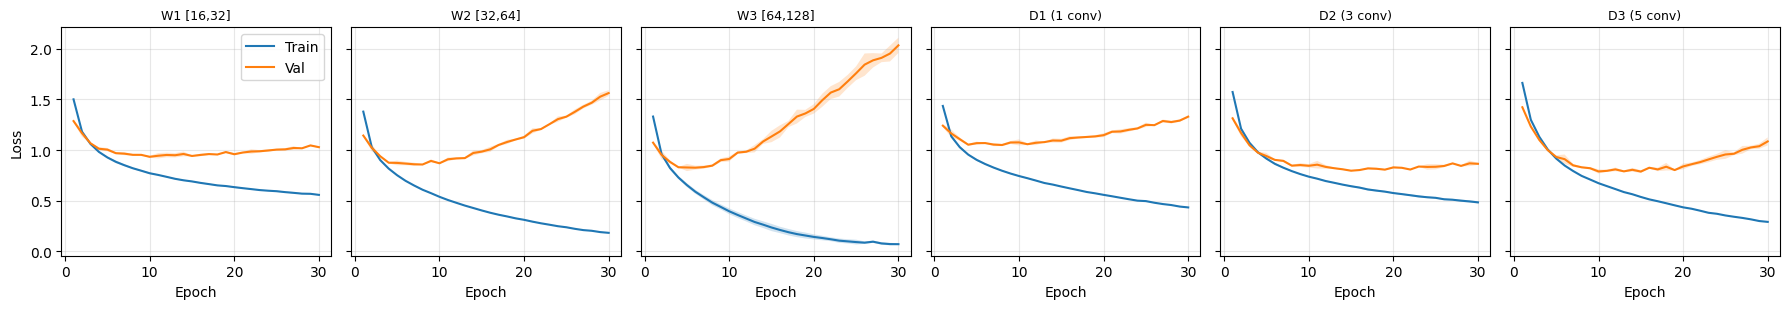

In [11]:
fig, ax = plt.subplots(1, 6, figsize=(18, 3.2), sharey=True)

e = np.arange(1, EPOCHS + 1)

for a, name in zip(ax, VARIANTS):

    for key, label in [
        ("train_loss", "Train"),
        ("val_loss", "Val")
    ]:
        curves = np.array([
            hists[(name, s)][key] for s in SEEDS
        ])

        m, sd = curves.mean(0), curves.std(0)

        a.plot(e, m, label=label)
        a.fill_between(e, m - sd, m + sd, alpha=0.2)

    a.set_title(name, fontsize=9)
    a.set_xlabel("Epoch")
    a.grid(alpha=.3)

ax[0].legend()
ax[0].set_ylabel("Loss")

plt.tight_layout()
plt.savefig("figures/ex4_loss_curves.png", dpi=200)
plt.show()